In [ ]:
from IPython.core.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pprint
import sys
np.set_printoptions(suppress=True, linewidth=200, threshold=1000000, precision=3, edgeitems=1000 )
from google.colab import drive
original_limit = sys.maxsize

from google.colab import drive

# Pipeline and column transformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer, make_column_transformer

# Data transformers
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, label_binarize, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

# Data splitter and model evaluator
from sklearn.model_selection import train_test_split, validation_curve, learning_curve, GridSearchCV

# Learning models
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.ensemble import BaggingClassifier, BaggingRegressor, GradientBoostingClassifier, GradientBoostingRegressor
from xgboost import XGBClassifier, XGBRegressor # need to install
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, f1_score, accuracy_score, confusion_matrix
from sklearn.metrics import roc_curve, auc, roc_auc_score

# Performance metrics
from sklearn.metrics import log_loss, roc_auc_score

In [ ]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
path='/content/drive/MyDrive/Science_Fair_Data_2025-2026/ConsolidatedCSV.csv'

In [ ]:
df=pd.read_csv(path)

In [ ]:
df

,Substance,Laser_Intenstity,Concentration,194.1151,196.1586,198.2017,200.2442,202.2863,204.3278,206.3688,...,3357.1519,3358.3602,3359.5684,3360.7764,3361.9843,3363.1921,3364.3998,3365.6074,3366.8148,3368.0221
0,Water,0.35,0.00000,204.7,204.7,204.7,204.7,204.7,204.7,204.7,...,7.8,4.9,3.1,-8.5,5.0,4.4,6.2,5.2,5.2,5.2
1,Water,0.40,0.00000,404.4,404.4,404.4,404.4,404.4,404.4,404.4,...,9.9,-0.5,3.1,0.8,4.2,3.8,2.9,6.0,6.0,6.0
2,Water,0.45,0.00000,607.3,607.3,607.3,607.3,607.3,607.3,607.3,...,15.6,13.8,9.9,10.2,18.2,15.3,17.0,6.2,6.2,6.2
3,Water,0.50,0.00000,866.9,866.9,866.9,866.9,866.9,866.9,866.9,...,17.7,18.7,20.2,21.8,24.7,23.7,19.4,14.3,14.3,14.3
4,Water,0.55,0.00000,1122.4,1122.4,1122.4,1122.4,1122.4,1122.4,1122.4,...,25.8,26.6,29.8,24.4,28.7,26.6,26.7,30.9,30.9,30.9
5,Water,0.60,0.00000,1314.5,1314.5,1314.5,1314.5,1314.5,1314.5,1314.5,...,25.3,23.6,30.7,30.0,24.4,17.1,22.8,25.7,25.7,25.7
6,Water,0.65,0.00000,1582.6,1582.6,1582.6,1582.6,1582.6,1582.6,1582.6,...,39.0,45.6,44.9,47.3,40.9,36.9,41.9,36.1,36.1,36.1
7,Water,0.70,0.00000,1841.4,1841.4,1841.4,1841.4,1841.4,1841.4,1841.4,...,49.8,50.4,50.4,41.9,42.5,45.1,51.5,60.8,60.8,60.8
8,T4 in Water,0.35,0.00021,180.3,180.3,180.3,180.3,180.3,180.3,180.3,...,7.6,8.7,5.6,4.8,5.6,-0.4,5.1,5.1,5.1,5.1
9,T4 in Water,0.40,0.00021,362.7,362.7,362.7,362.7,362.7,362.7,362.7,...,18.7,12.0,9.6,15.3,11.2,7.6,2.1,-0.8,-0.8,-0.8


In [ ]:
cat_col = ['Concentration']

In [ ]:
num_col = ['Laser_Intenstity','194.1151','196.1586','198.2017','200.2442','202.2863','204.3278','206.3688','208.4094','210.4494','212.4889','214.528','216.5665','218.6045','220.6421','222.6791','224.7156','226.7517','228.7872','230.8222','232.8567','234.8907','236.9242','238.9572','240.9897','243.0217','245.0532','247.0842','249.1147','251.1446','253.1741','255.2031','257.2315','259.2594','261.2869','263.3138','265.3402','267.3661','269.3915','271.4164','273.4408','275.4647','277.488','279.5109','281.5332','283.555','285.5764','287.5972','289.6175','291.6372','293.6565','295.6753','297.6935','299.7112','301.7285','303.7452','305.7614','307.777','309.7922','311.8069','313.821','315.8346','317.8477','319.8603','321.8724','323.8839','325.895','327.9055','329.9155','331.925','333.934','335.9424','337.9504','339.9578','341.9647','343.9711','345.9769','347.9823','349.9871','351.9914','353.9952','355.9985','358.0012','360.0034','362.0051','364.0063','366.007','368.0071','370.0067','372.0058','374.0044','376.0025','378','379.997','381.9935','383.9895','385.9849','387.9798','389.9742','391.9681','393.9614','395.9542','397.9465','399.9383','401.9295','403.9203','405.9104','407.9001','409.8893','411.8779','413.866','415.8535','417.8406','419.8271','421.813','423.7985','425.7834','427.7678','429.7517','431.735','433.7178','435.7001','437.6819','439.6631','441.6438','443.624','445.6036','447.5827','449.5613','451.5394','453.5169','455.4939','457.4703','459.4462','461.4216','463.3965','465.3708','467.3446','469.3179','471.2906','473.2628','475.2345','477.2056','479.1763','481.1463','483.1159','485.0849','487.0533','489.0213','490.9887','492.9556','494.9219','496.8877','498.853','500.8177','502.7819','504.7456','506.7087','508.6713','510.6334','512.5949','514.5559','516.5163','518.4762','520.4356','522.3944','524.3528','526.3105','528.2678','530.2245','532.1806','534.1362','536.0913','538.0459','539.9999','541.9533','543.9063','545.8587','547.8105','549.7618','551.7126','553.6628','555.6125','557.5617','559.5103','561.4584','563.4059','565.3529','567.2994','569.2453','571.1907','573.1356','575.0799','577.0236','578.9668','580.9095','582.8517','584.7933','586.7343','588.6748','590.6148','592.5542','594.4931','596.4315','598.3693','600.3065','602.2433','604.1794','606.1151','608.0502','609.9847','611.9187','613.8522','615.7851','617.7175','619.6494','621.5807','623.5114','625.4416','627.3713','629.3004','631.229','633.157','635.0845','637.0114','638.9378','640.8637','642.789','644.7138','646.638','648.5617','650.4848','652.4074','654.3294','656.2509','658.1719','660.0923','662.0121','663.9314','665.8502','667.7684','669.6861','671.6032','673.5198','675.4359','677.3513','679.2663','681.1807','683.0945','685.0078','686.9206','688.8328','690.7445','692.6556','694.5662','696.4762','698.3857','700.2946','702.203','704.1108','706.0181','707.9248','709.831','711.7367','713.6418','715.5463','717.4503','719.3538','721.2567','723.159','725.0608','726.9621','728.8628','730.7629','732.6626','734.5616','736.4601','738.3581','740.2555','742.1524','744.0487','745.9445','747.8397','749.7344','751.6285','753.522','755.4151','757.3075','759.1995','761.0908','762.9817','764.8719','766.7617','768.6508','770.5395','772.4275','774.3151','776.202','778.0885','779.9743','781.8597','783.7444','785.6287','787.5123','789.3955','791.278','793.1601','795.0415','796.9225','798.8028','800.6827','802.5619','804.4406','806.3188','808.1964','810.0735','811.95','813.826','815.7014','817.5763','819.4506','821.3243','823.1975','825.0702','826.9423','828.8139','830.6849','832.5553','834.4252','836.2946','838.1634','840.0316','841.8993','843.7665','845.6331','847.4991','849.3646','851.2296','853.094','854.9578','856.8211','858.6838','860.546','862.4076','864.2687','866.1292','867.9892','869.8486','871.7075','873.5658','875.4236','877.2808','879.1375','880.9936','882.8492','884.7042','886.5586','888.4125','890.2659','892.1187','893.9709','895.8226','897.6738','899.5244','901.3744','903.2239','905.0729','906.9213','908.7691','910.6164','912.4631','914.3093','916.1549','918','919.8445','921.6885','923.5319','925.3748','927.2171','929.0589','930.9001','932.7407','934.5809','936.4204','938.2594','940.0979','941.9358','943.7731','945.6099','947.4462','949.2819','951.117','952.9516','954.7857','956.6191','958.4521','960.2845','962.1163','963.9476','965.7783','967.6085','969.4381','971.2672','973.0957','974.9237','976.7511','978.578','980.4043','982.2301','984.0553','985.8799','987.704','989.5276','991.3506','993.1731','994.995','996.8163','998.6371','1000.4574','1002.2771','1004.0962','1005.9148','1007.7329','1009.5504','1011.3673','1013.1837','1014.9996','1016.8149','1018.6296','1020.4438','1022.2574','1024.0705','1025.8831','1027.695','1029.5065','1031.3174','1033.1277','1034.9375','1036.7467','1038.5554','1040.3635','1042.1711','1043.9782','1045.7846','1047.5906','1049.396','1051.2008','1053.0051','1054.8088','1056.612','1058.4146','1060.2167','1062.0182','1063.8192','1065.6196','1067.4195','1069.2189','1071.0176','1072.8159','1074.6136','1076.4107','1078.2073','1080.0033','1081.7988','1083.5937','1085.3881','1087.182','1088.9752','1090.768','1092.5602','1094.3518','1096.1429','1097.9335','1099.7235','1101.5129','1103.3018','1105.0901','1106.878','1108.6652','1110.4519','1112.2381','1114.0237','1115.8087','1117.5932','1119.3772','1121.1606','1122.9435','1124.7258','1126.5076','1128.2888','1130.0695','1131.8496','1133.6292','1135.4082','1137.1867','1138.9647','1140.742','1142.5189','1144.2952','1146.0709','1147.8461','1149.6208','1151.3949','1153.1685','1154.9415','1156.714','1158.4859','1160.2573','1162.0281','1163.7984','1165.5681','1167.3373','1169.106','1170.8741','1172.6416','1174.4086','1176.1751','1177.941','1179.7064','1181.4712','1183.2355','1184.9992','1186.7624','1188.5251','1190.2872','1192.0487','1193.8097','1195.5702','1197.3301','1199.0895','1200.8483','1202.6066','1204.3644','1206.1216','1207.8782','1209.6343','1211.3899','1213.1449','1214.8994','1216.6534','1218.4068','1220.1596','1221.9119','1223.6637','1225.4149','1227.1656','1228.9157','1230.6653','1232.4144','1234.1629','1235.9108','1237.6582','1239.4051','1241.1515','1242.8973','1244.6425','1246.3872','1248.1314','1249.875','1251.6181','1253.3607','1255.1027','1256.8441','1258.585','1260.3254','1262.0653','1263.8046','1265.5433','1267.2815','1269.0192','1270.7563','1272.4929','1274.229','1275.9645','1277.6995','1279.4339','1281.1678','1282.9012','1284.634','1286.3663','1288.098','1289.8292','1291.5599','1293.29','1295.0196','1296.7486','1298.4771','1300.2051','1301.9325','1303.6594','1305.3858','1307.1116','1308.8368','1310.5616','1312.2858','1314.0094','1315.7326','1317.4552','1319.1772','1320.8987','1322.6197','1324.3401','1326.0601','1327.7794','1329.4982','1331.2165','1332.9343','1334.6515','1336.3682','1338.0844','1339.8','1341.5151','1343.2296','1344.9436','1346.6571','1348.37','1350.0824','1351.7943','1353.5056','1355.2164','1356.9267','1358.6364','1360.3456','1362.0543','1363.7624','1365.47','1367.1771','1368.8836','1370.5896','1372.2951','1374','1375.7044','1377.4083','1379.1116','1380.8144','1382.5167','1384.2184','1385.9196','1387.6203','1389.3204','1391.02','1392.7191','1394.4176','1396.1157','1397.8131','1399.5101','1401.2065','1402.9024','1404.5978','1406.2926','1407.9869','1409.6807','1411.3739','1413.0666','1414.7588','1416.4504','1418.1416','1419.8322','1421.5222','1423.2118','1424.9008','1426.5892','1428.2772','1429.9646','1431.6515','1433.3379','1435.0237','1436.709','1438.3938','1440.0781','1441.7618','1443.445','1445.1277','1446.8098','1448.4914','1450.1725','1451.8531','1453.5331','1455.2127','1456.8917','1458.5701','1460.2481','1461.9255','1463.6024','1465.2787','1466.9546','1468.6299','1470.3047','1471.9789','1473.6527','1475.3259','1476.9986','1478.6708','1480.3424','1482.0135','1483.6841','1485.3542','1487.0238','1488.6928','1490.3613','1492.0293','1493.6968','1495.3637','1497.0301','1498.696','1500.3614','1502.0263','1503.6906','1505.3544','1507.0177','1508.6805','1510.3427','1512.0045','1513.6657','1515.3264','1516.9866','1518.6462','1520.3053','1521.964','1523.622','1525.2796','1526.9367','1528.5932','1530.2492','1531.9047','1533.5597','1535.2142','1536.8681','1538.5216','1540.1745','1541.8269','1543.4788','1545.1301','1546.781','1548.4313','1550.0811','1551.7304','1553.3792','1555.0274','1556.6752','1558.3224','1559.9692','1561.6154','1563.261','1564.9062','1566.5509','1568.195','1569.8387','1571.4818','1573.1244','1574.7665','1576.408','1578.0491','1579.6896','1581.3297','1582.9692','1584.6082','1586.2467','1587.8847','1589.5222','1591.1591','1592.7956','1594.4315','1596.067','1597.7019','1599.3363','1600.9702','1602.6036','1604.2365','1605.8688','1607.5007','1609.132','1610.7629','1612.3932','1614.023','1615.6523','1617.2811','1618.9094','1620.5372','1622.1645','1623.7912','1625.4175','1627.0433','1628.6685','1630.2932','1631.9175','1633.5412','1635.1644','1636.7871','1638.4093','1640.031','1641.6522','1643.2729','1644.8931','1646.5128','1648.1319','1649.7506','1651.3688','1652.9864','1654.6036','1656.2202','1657.8364','1659.452','1661.0672','1662.6818','1664.2959','1665.9096','1667.5227','1669.1353','1670.7475','1672.3591','1673.9702','1675.5808','1677.1909','1678.8005','1680.4097','1682.0183','1683.6264','1685.234','1686.8411','1688.4477','1690.0538','1691.6595','1693.2646','1694.8692','1696.4733','1698.0769','1699.68','1701.2827','1702.8848','1704.4864','1706.0876','1707.6882','1709.2883','1710.888','1712.4871','1714.0857','1715.6839','1717.2815','1718.8787','1720.4754','1722.0715','1723.6672','1725.2624','1726.857','1728.4512','1730.0449','1731.6381','1733.2308','1734.823','1736.4147','1738.006','1739.5967','1741.1869','1742.7767','1744.3659','1745.9547','1747.5429','1749.1307','1750.718','1752.3048','1753.8911','1755.4769','1757.0622','1758.647','1760.2314','1761.8152','1763.3986','1764.9814','1766.5638','1768.1457','1769.7271','1771.308','1772.8884','1774.4684','1776.0478','1777.6268','1779.2053','1780.7832','1782.3607','1783.9377','1785.5143','1787.0903','1788.6659','1790.2409','1791.8155','1793.3896','1794.9632','1796.5363','1798.109','1799.6811','1801.2528','1802.824','1804.3947','1805.9649','1807.5346','1809.1039','1810.6726','1812.2409','1813.8087','1815.376','1816.9429','1818.5092','1820.0751','1821.6405','1823.2054','1824.7698','1826.3338','1827.8972','1829.4602','1831.0227','1832.5848','1834.1463','1835.7074','1837.268','1838.8281','1840.3877','1841.9469','1843.5055','1845.0637','1846.6215','1848.1787','1849.7355','1851.2917','1852.8476','1854.4029','1855.9577','1857.5121','1859.066','1860.6195','1862.1724','1863.7249','1865.2769','1866.8284','1868.3795','1869.9301','1871.4802','1873.0298','1874.579','1876.1277','1877.6759','1879.2236','1880.7709','1882.3177','1883.864','1885.4099','1886.9552','1888.5002','1890.0446','1891.5886','1893.1321','1894.6751','1896.2176','1897.7597','1899.3014','1900.8425','1902.3832','1903.9234','1905.4631','1907.0024','1908.5412','1910.0796','1911.6174','1913.1548','1914.6918','1916.2282','1917.7642','1919.2998','1920.8348','1922.3694','1923.9036','1925.4373','1926.9705','1928.5032','1930.0355','1931.5673','1933.0986','1934.6295','1936.16','1937.6899','1939.2194','1940.7484','1942.277','1943.8051','1945.3328','1946.86','1948.3867','1949.9129','1951.4387','1952.9641','1954.489','1956.0134','1957.5373','1959.0608','1960.5839','1962.1064','1963.6286','1965.1502','1966.6714','1968.1922','1969.7125','1971.2323','1972.7517','1974.2706','1975.789','1977.307','1978.8246','1980.3416','1981.8583','1983.3745','1984.8902','1986.4054','1987.9202','1989.4346','1990.9485','1992.4619','1993.9749','1995.4875','1996.9996','1998.5112','2000.0224','2001.5331','2003.0434','2004.5532','2006.0625','2007.5715','2009.0799','2010.5879','2012.0955','2013.6026','2015.1093','2016.6155','2018.1213','2019.6266','2021.1314','2022.6358','2024.1398','2025.6433','2027.1464','2028.649','2030.1512','2031.6529','2033.1542','2034.655','2036.1554','2037.6554','2039.1548','2040.6539','2042.1525','2043.6507','2045.1484','2046.6456','2048.1424','2049.6388','2051.1348','2052.6302','2054.1253','2055.6199','2057.1141','2058.6078','2060.101','2061.5939','2063.0863','2064.5782','2066.0697','2067.5608','2069.0514','2070.5416','2072.0313','2073.5207','2075.0095','2076.4979','2077.9859','2079.4735','2080.9606','2082.4473','2083.9335','2085.4193','2086.9046','2088.3896','2089.874','2091.3581','2092.8417','2094.3249','2095.8076','2097.2899','2098.7718','2100.2532','2101.7342','2103.2148','2104.6949','2106.1746','2107.6539','2109.1327','2110.6111','2112.089','2113.5666','2115.0437','2116.5203','2117.9966','2119.4724','2120.9477','2122.4227','2123.8972','2125.3712','2126.8449','2128.3181','2129.7909','2131.2633','2132.7352','2134.2067','2135.6778','2137.1484','2138.6186','2140.0884','2141.5578','2143.0267','2144.4952','2145.9633','2147.4309','2148.8982','2150.365','2151.8313','2153.2973','2154.7628','2156.2279','2157.6926','2159.1568','2160.6207','2162.0841','2163.5471','2165.0096','2166.4718','2167.9335','2169.3948','2170.8556','2172.3161','2173.7761','2175.2357','2176.6949','2178.1537','2179.612','2181.0699','2182.5275','2183.9845','2185.4412','2186.8975','2188.3533','2189.8087','2191.2637','2192.7183','2194.1724','2195.6262','2197.0795','2198.5324','2199.9849','2201.437','2202.8887','2204.3399','2205.7907','2207.2412','2208.6912','2210.1407','2211.5899','2213.0387','2214.487','2215.935','2217.3825','2218.8296','2220.2763','2221.7226','2223.1685','2224.6139','2226.059','2227.5036','2228.9479','2230.3917','2231.8351','2233.2781','2234.7207','2236.1629','2237.6047','2239.046','2240.487','2241.9275','2243.3677','2244.8074','2246.2467','2247.6857','2249.1242','2250.5623','2252','2253.4373','2254.8742','2256.3107','2257.7468','2259.1825','2260.6177','2262.0526','2263.4871','2264.9211','2266.3548','2267.7881','2269.2209','2270.6534','2272.0854','2273.5171','2274.9483','2276.3792','2277.8096','2279.2397','2280.6694','2282.0986','2283.5275','2284.9559','2286.384','2287.8116','2289.2389','2290.6657','2292.0922','2293.5183','2294.9439','2296.3692','2297.7941','2299.2186','2300.6427','2302.0663','2303.4896','2304.9125','2306.335','2307.7571','2309.1789','2310.6002','2312.0211','2313.4417','2314.8618','2316.2815','2317.7009','2319.1199','2320.5384','2321.9566','2323.3744','2324.7918','2326.2088','2327.6255','2329.0417','2330.4575','2331.873','2333.288','2334.7027','2336.117','2337.5309','2338.9444','2340.3575','2341.7703','2343.1826','2344.5946','2346.0062','2347.4174','2348.8282','2350.2386','2351.6486','2353.0583','2354.4675','2355.8764','2357.2849','2358.693','2360.1008','2361.5081','2362.9151','2364.3217','2365.7279','2367.1337','2368.5391','2369.9442','2371.3488','2372.7531','2374.1571','2375.5606','2376.9638','2378.3665','2379.7689','2381.1709','2382.5726','2383.9739','2385.3747','2386.7752','2388.1754','2389.5751','2390.9745','2392.3735','2393.7721','2395.1704','2396.5683','2397.9658','2399.3629','2400.7596','2402.156','2403.552','2404.9476','2406.3429','2407.7378','2409.1323','2410.5264','2411.9202','2413.3136','2414.7066','2416.0993','2417.4915','2418.8835','2420.275','2421.6662','2423.057','2424.4474','2425.8375','2427.2272','2428.6165','2430.0054','2431.394','2432.7823','2434.1701','2435.5576','2436.9447','2438.3315','2439.7179','2441.1039','2442.4896','2443.8749','2445.2598','2446.6444','2448.0286','2449.4124','2450.7959','2452.179','2453.5617','2454.9441','2456.3262','2457.7078','2459.0891','2460.4701','2461.8506','2463.2309','2464.6107','2465.9902','2467.3694','2468.7481','2470.1266','2471.5046','2472.8823','2474.2597','2475.6367','2477.0133','2478.3896','2479.7655','2481.1411','2482.5163','2483.8911','2485.2656','2486.6398','2488.0135','2489.387','2490.76','2492.1328','2493.5051','2494.8771','2496.2488','2497.6201','2498.9911','2500.3617','2501.7319','2503.1018','2504.4714','2505.8406','2507.2094','2508.5779','2509.9461','2511.3139','2512.6813','2514.0484','2515.4152','2516.7816','2518.1476','2519.5133','2520.8787','2522.2437','2523.6084','2524.9727','2526.3367','2527.7003','2529.0636','2530.4265','2531.7891','2533.1514','2534.5133','2535.8748','2537.2361','2538.5969','2539.9575','2541.3176','2542.6775','2544.037','2545.3962','2546.755','2548.1135','2549.4716','2550.8294','2552.1868','2553.544','2554.9007','2556.2572','2557.6133','2558.9691','2560.3245','2561.6796','2563.0343','2564.3887','2565.7428','2567.0965','2568.4499','2569.803','2571.1557','2572.5081','2573.8602','2575.2119','2576.5633','2577.9144','2579.2651','2580.6155','2581.9655','2583.3153','2584.6646','2586.0137','2587.3624','2588.7108','2590.0589','2591.4066','2592.754','2594.1011','2595.4479','2596.7943','2598.1404','2599.4861','2600.8315','2602.1766','2603.5214','2604.8658','2606.21','2607.5538','2608.8972','2610.2404','2611.5832','2612.9256','2614.2678','2615.6096','2616.9511','2618.2923','2619.6332','2620.9737','2622.3139','2623.6538','2624.9934','2626.3326','2627.6716','2629.0102','2630.3485','2631.6864','2633.024','2634.3614','2635.6984','2637.035','2638.3714','2639.7074','2641.0432','2642.3786','2643.7136','2645.0484','2646.3828','2647.717','2649.0508','2650.3843','2651.7175','2653.0503','2654.3829','2655.7151','2657.047','2658.3786','2659.7099','2661.0409','2662.3715','2663.7019','2665.0319','2666.3616','2667.6911','2669.0202','2670.3489','2671.6774','2673.0056','2674.3334','2675.661','2676.9882','2678.3151','2679.6417','2680.968','2682.294','2683.6197','2684.9451','2686.2701','2687.5949','2688.9194','2690.2435','2691.5673','2692.8909','2694.2141','2695.537','2696.8596','2698.182','2699.504','2700.8257','2702.1471','2703.4682','2704.789','2706.1094','2707.4296','2708.7495','2710.0691','2711.3884','2712.7074','2714.026','2715.3444','2716.6625','2717.9803','2719.2977','2720.6149','2721.9318','2723.2484','2724.5647','2725.8806','2727.1963','2728.5117','2729.8268','2731.1416','2732.4561','2733.7703','2735.0842','2736.3978','2737.7111','2739.0242','2740.3369','2741.6493','2742.9614','2744.2733','2745.5848','2746.8961','2748.2071','2749.5177','2750.8281','2752.1382','2753.448','2754.7575','2756.0667','2757.3757','2758.6843','2759.9927','2761.3007','2762.6085','2763.916','2765.2232','2766.5301','2767.8367','2769.143','2770.4491','2771.7548','2773.0603','2774.3655','2775.6704','2776.975','2778.2793','2779.5834','2780.8871','2782.1906','2783.4938','2784.7967','2786.0993','2787.4017','2788.7037','2790.0055','2791.307','2792.6082','2793.9092','2795.2098','2796.5102','2797.8103','2799.1101','2800.4096','2801.7089','2803.0079','2804.3066','2805.605','2806.9032','2808.201','2809.4986','2810.7959','2812.093','2813.3897','2814.6862','2815.9824','2817.2784','2818.574','2819.8694','2821.1645','2822.4594','2823.7539','2825.0482','2826.3422','2827.636','2828.9295','2830.2227','2831.5156','2832.8083','2834.1006','2835.3928','2836.6846','2837.9762','2839.2675','2840.5586','2841.8493','2843.1398','2844.4301','2845.72','2847.0097','2848.2992','2849.5884','2850.8773','2852.1659','2853.4543','2854.7424','2856.0302','2857.3178','2858.6051','2859.8921','2861.1789','2862.4655','2863.7517','2865.0377','2866.3234','2867.6089','2868.8941','2870.1791','2871.4638','2872.7482','2874.0323','2875.3163','2876.5999','2877.8833','2879.1664','2880.4493','2881.7319','2883.0143','2884.2963','2885.5782','2886.8598','2888.1411','2889.4222','2890.703','2891.9835','2893.2638','2894.5439','2895.8237','2897.1032','2898.3825','2899.6615','2900.9403','2902.2188','2903.4971','2904.7751','2906.0529','2907.3304','2908.6077','2909.8847','2911.1614','2912.4379','2913.7142','2914.9902','2916.266','2917.5415','2918.8168','2920.0918','2921.3665','2922.6411','2923.9153','2925.1894','2926.4631','2927.7367','2929.01','2930.283','2931.5558','2932.8284','2934.1007','2935.3727','2936.6445','2937.9161','2939.1875','2940.4585','2941.7294','2943','2944.2704','2945.5405','2946.8104','2948.08','2949.3494','2950.6186','2951.8875','2953.1562','2954.4246','2955.6928','2956.9608','2958.2285','2959.496','2960.7632','2962.0302','2963.297','2964.5636','2965.8299','2967.0959','2968.3618','2969.6273','2970.8927','2972.1578','2973.4227','2974.6874','2975.9518','2977.216','2978.48','2979.7437','2981.0072','2982.2704','2983.5335','2984.7963','2986.0588','2987.3212','2988.5833','2989.8452','2991.1068','2992.3682','2993.6294','2994.8904','2996.1511','2997.4116','2998.6719','2999.932','3001.1918','3002.4514','3003.7108','3004.9699','3006.2288','3007.4875','3008.746','3010.0043','3011.2623','3012.5201','3013.7777','3015.035','3016.2921','3017.549','3018.8057','3020.0622','3021.3184','3022.5745','3023.8303','3025.0858','3026.3412','3027.5963','3028.8513','3030.106','3031.3605','3032.6147','3033.8688','3035.1226','3036.3762','3037.6296','3038.8828','3040.1358','3041.3885','3042.641','3043.8934','3045.1455','3046.3973','3047.649','3048.9005','3050.1517','3051.4027','3052.6536','3053.9042','3055.1546','3056.4048','3057.6547','3058.9045','3060.154','3061.4034','3062.6525','3063.9014','3065.1501','3066.3986','3067.6469','3068.895','3070.1429','3071.3905','3072.638','3073.8852','3075.1323','3076.3791','3077.6258','3078.8722','3080.1184','3081.3644','3082.6102','3083.8558','3085.1012','3086.3464','3087.5914','3088.8362','3090.0808','3091.3252','3092.5694','3093.8134','3095.0571','3096.3007','3097.5441','3098.7873','3100.0302','3101.273','3102.5156','3103.758','3105.0002','3106.2421','3107.4839','3108.7255','3109.9669','3111.2081','3112.4491','3113.6899','3114.9305','3116.1709','3117.4111','3118.6511','3119.891','3121.1306','3122.37','3123.6093','3124.8483','3126.0872','3127.3258','3128.5643','3129.8026','3131.0407','3132.2786','3133.5163','3134.7538','3135.9911','3137.2282','3138.4652','3139.7019','3140.9385','3142.1749','3143.411','3144.647','3145.8829','3147.1185','3148.3539','3149.5892','3150.8242','3152.0591','3153.2938','3154.5283','3155.7626','3156.9968','3158.2307','3159.4645','3160.6981','3161.9315','3163.1647','3164.3978','3165.6306','3166.8633','3168.0958','3169.3281','3170.5602','3171.7922','3173.024','3174.2556','3175.487','3176.7182','3177.9493','3179.1801','3180.4108','3181.6413','3182.8717','3184.1019','3185.3318','3186.5617','3187.7913','3189.0208','3190.25','3191.4791','3192.7081','3193.9368','3195.1654','3196.3938','3197.6221','3198.8502','3200.078','3201.3058','3202.5333','3203.7607','3204.9879','3206.2149','3207.4418','3208.6685','3209.895','3211.1214','3212.3476','3213.5736','3214.7994','3216.0251','3217.2506','3218.476','3219.7011','3220.9261','3222.151','3223.3757','3224.6002','3225.8245','3227.0487','3228.2727','3229.4966','3230.7203','3231.9438','3233.1671','3234.3903','3235.6134','3236.8362','3238.0589','3239.2815','3240.5039','3241.7261','3242.9482','3244.1701','3245.3918','3246.6134','3247.8348','3249.0561','3250.2772','3251.4981','3252.7189','3253.9395','3255.16','3256.3803','3257.6005','3258.8205','3260.0403','3261.26','3262.4796','3263.6989','3264.9182','3266.1372','3267.3561','3268.5749','3269.7935','3271.012','3272.2303','3273.4484','3274.6664','3275.8843','3277.102','3278.3195','3279.5369','3280.7541','3281.9712','3283.1882','3284.405','3285.6216','3286.8381','3288.0545','3289.2707','3290.4867','3291.7026','3292.9184','3294.134','3295.3494','3296.5648','3297.7799','3298.995','3300.2098','3301.4246','3302.6392','3303.8536','3305.0679','3306.2821','3307.4961','3308.71','3309.9237','3311.1373','3312.3507','3313.5641','3314.7772','3315.9902','3317.2031','3318.4159','3319.6285','3320.841','3322.0533','3323.2655','3324.4775','3325.6894','3326.9012','3328.1129','3329.3244','3330.5357','3331.7469','3332.958','3334.169','3335.3798','3336.5905','3337.8011','3339.0115','3340.2218','3341.4319','3342.6419','3343.8518','3345.0616','3346.2712','3347.4807','3348.69','3349.8992','3351.1083','3352.3173','3353.5261','3354.7348','3355.9434','3357.1519','3358.3602','3359.5684','3360.7764','3361.9843','3363.1921','3364.3998','3365.6074','3366.8148','3368.0221']

In [ ]:
# Define X and y
X = df[cat_col + num_col]
y = df['Substance']
#y = y_train['Substance']
encoder = LabelEncoder()
encoder.fit(y)
y = encoder.transform(y)
encoder_name_mapping_y = dict(zip(encoder.classes_, encoder.transform(encoder.classes_)))
print(encoder_name_mapping_y)

{'T4 Raw': np.int64(0), 'T4 in Water': np.int64(1), 'T4 in Water, Colloid, Milk, India Ink solution': np.int64(2), 'Water': np.int64(3)}


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.3,
                                                    stratify=y,     # for classification tasks only, delete this for regression tasks
                                                    random_state=0
                                                   )

In [ ]:
cat_pipe = make_pipeline(SimpleImputer(strategy='most_frequent'),
                         OneHotEncoder(handle_unknown='ignore')
                       )

num_pipe = make_pipeline(SimpleImputer(strategy='mean'),
                         StandardScaler()
                        )

# Main pipe
pipe = make_pipeline(ColumnTransformer( [  ('cat', cat_pipe, cat_col),
                                          ('num', num_pipe, num_col) ],
                                           sparse_threshold=0
                                            ),
                     # If using PCA or LDA leads to an error related to sparse input, you can fix it by
                     # adding 'sparse_threshold=0' in the above ColumnTransformer, that is
                     # the last line should read as ... ('num', num_pipe, num_col) ], sparse_threshold=0 ),
                     #PCA(n_components=10),
                     #LDA(n_components=3),

                     ######################################################################
                     # Here you choose a classification model
                     #
                     #SVC(kernel='rbf', C=1, gamma=0.01, probability=True)
                     #SVC(kernel='linear', C=1, gamma=0.01, probability=True)
                     #LogisticRegression(solver='liblinear', C=1, penalty='l1')
                     #DecisionTreeClassifier(criterion='gini', max_depth=8, min_samples_leaf=5, random_state=1)
                     #RandomForestClassifier(criterion='gini', n_estimators=100, max_depth=8, min_samples_leaf=1, random_state=1)
                     #KNeighborsClassifier(n_neighbors=5, p=2)
                     #GradientBoostingClassifier(n_estimators=100, max_depth=2, min_samples_leaf=1, learning_rate=0.1, random_state=1)
                     XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, random_state=1)

                     ######################################################################
                     # Here you choose a regression model
                     #
                     #Ridge(alpha = 0.1)
                     #Lasso(alpha = 0.1)
                     #DecisionTreeRegressor(n_estimators=100, max_depth=8, min_samples_leaf=5, random_state=1)
                     #RandomForestRegressor(n_estimators=100, max_depth=8, min_samples_leaf=5, random_state=1)
                     #GradientBoostingRegressor(n_estimators=100, max_depth=3, min_samples_leaf=1, learning_rate=0.1, random_state=1)
                     #XGBRegressor(n_estimators=100, max_depth=3, learning_rate=0.1, random_state=1)
                    )

######################################################################
# Fit the untuned model, just try to test the codes

pipe.fit(X_train,y_train)


######################################################################
# If your model is a classification problem, the score is the accuracy
# If your model is a regression problem, then score is the R^2
# Always check the meaning of 'score' of the model in sklearn documentation

print('Training score:', pipe.score(X_train,y_train))
print('Test score:    ', pipe.score(X_test,y_test))



######################################################################
# For classification problems, check how balanced your target variable is:

print('\ny_train hist: \n', pd.Series(y_train).value_counts())
print('\ny_train dist: \n', pd.Series(y_train).value_counts() / len(y_train))


######################################################################
# If the data is not quite balanced, then it is better to look at other metrics:

print('\nMeasuring performance using log loss (the lower the better):')
print('Training set log loss:', log_loss(y_train, pipe.predict_proba(X_train)))
print('Test set     log loss:', log_loss(y_test,  pipe.predict_proba(X_test)))

Training score: 1.0
Test score:     1.0

y_train hist: 
 1    10
2     8
3     6
0     6
Name: count, dtype: int64

y_train dist: 
 1    0.333333
2    0.266667
3    0.200000
0    0.200000
Name: count, dtype: float64

Measuring performance using log loss (the lower the better):
Training set log loss: 0.06891883856991657
Test set     log loss: 0.0969177946035355


In [ ]:
print('\nMeasuring performance using roc_auc  (the higher the better: highest possible is 1, random guess is 0.5):')
print('Training set roc auc:', roc_auc_score(y_train, pipe.predict_proba(X_train), multi_class='ovr', average='macro'))
print('Test set     roc auc:', roc_auc_score(y_test,  pipe.predict_proba(X_test), multi_class='ovr', average='macro'))


Measuring performance using roc_auc  (the higher the better: highest possible is 1, random guess is 0.5):
Training set roc auc: 1.0
Test set     roc auc: 1.0


# **PCA Analysis**

In [ ]:
# Standardizing data
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
sc.fit(X_train)
X_train = sc.transform(X_train)
X_test = sc.transform(X_test)

from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(C=10, solver='liblinear', multi_class='ovr')
lr = lr.fit(X_train, y_train)
lr.fit(X_train, y_train)
print("Logistic Regression Training accuracy: ", lr.score(X_train, y_train))
print("Logistic Regression Test accuracy: ", lr.score(X_test, y_test))
print()

from sklearn.ensemble import GradientBoostingClassifier
gbc = GradientBoostingClassifier(n_estimators=100, max_depth=2, min_samples_leaf=1, learning_rate=0.1, random_state=1)
gbc = gbc.fit(X_train, y_train)
gbc.fit(X_train, y_train)
print("Gradient Boosting Training accuracy: ", gbc.score(X_train, y_train))
print("Gradient Boosting Test accuracy: ", gbc.score(X_test, y_test))
print()

from xgboost import XGBClassifier
xgb = XGBClassifier(n_estimators=200, max_depth=100, learning_rate=0.1, random_state=1)
xgb = xgb.fit(X_train, y_train)
xgb.fit(X_train, y_train)
print("XGBoost Training accuracy: ", xgb.score(X_train, y_train))
print("XGBoost Test accuracy: ", xgb.score(X_test, y_test))


Logistic Regression Training accuracy:  1.0
Logistic Regression Test accuracy:  0.46153846153846156



/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


Gradient Boosting Training accuracy:  1.0
Gradient Boosting Test accuracy:  0.8461538461538461

XGBoost Training accuracy:  1.0
XGBoost Test accuracy:  0.6923076923076923


In [ ]:
from sklearn.decomposition import PCA
pca = PCA()
pca.fit(X_train)

ev = pca.explained_variance_ratio_

with np.printoptions(precision=3):
    print('Fraction of variance explained by each PC =', ev)
    print('Cumulative fraction of variance explained =', np.cumsum(ev))

Fraction of variance explained by each PC = [0.889 0.099 0.006 0.001 0.001 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.   ]
Cumulative fraction of variance explained = [0.889 0.988 0.994 0.995 0.996 0.996 0.997 0.997 0.997 0.998 0.998 0.998 0.998 0.998 0.998 0.999 0.999 0.999 0.999 0.999 0.999 0.999 0.999 1.    1.    1.    1.    1.    1.    1.   ]


In [ ]:
print( np.c_[np.round(pca.components_[0],2), df.columns[1:]] )

[[0.02 'Laser_Intenstity']
 [0.01 'Concentration']
 [0.02 '194.1151']
 [0.02 '196.1586']
 [0.02 '198.2017']
 [0.02 '200.2442']
 [0.02 '202.2863']
 [0.02 '204.3278']
 [0.02 '206.3688']
 [0.02 '208.4094']
 [0.02 '210.4494']
 [0.02 '212.4889']
 [0.02 '214.528']
 [0.02 '216.5665']
 [0.02 '218.6045']
 [0.02 '220.6421']
 [0.02 '222.6791']
 [0.02 '224.7156']
 [0.02 '226.7517']
 [0.02 '228.7872']
 [0.02 '230.8222']
 [0.02 '232.8567']
 [0.02 '234.8907']
 [0.02 '236.9242']
 [0.02 '238.9572']
 [0.02 '240.9897']
 [0.02 '243.0217']
 [0.02 '245.0532']
 [0.02 '247.0842']
 [0.02 '249.1147']
 [0.02 '251.1446']
 [0.02 '253.1741']
 [0.02 '255.2031']
 [0.02 '257.2315']
 [0.02 '259.2594']
 [0.02 '261.2869']
 [0.02 '263.3138']
 [0.02 '265.3402']
 [0.02 '267.3661']
 [0.02 '269.3915']
 [0.02 '271.4164']
 [0.02 '273.4408']
 [0.02 '275.4647']
 [0.02 '277.488']
 [0.02 '279.5109']
 [0.02 '281.5332']
 [0.02 '283.555']
 [0.02 '285.5764']
 [0.02 '287.5972']
 [0.02 '289.6175']
 [0.02 '291.6372']
 [0.02 '293.6565']
 [

In [ ]:
pca = PCA(n_components=2)
pca.fit(X_train)
pca.transform(X_train)

array([[-20.653,  -7.607],
       [-17.932,  -5.811],
       [-24.021,  -9.775],
       [ -7.762,  26.185],
       [-12.49 ,  15.323],
       [-19.068,  -7.703],
       [-15.903,  -2.215],
       [-20.749,  -3.999],
       [ -6.587,  27.333],
       [-11.043,  17.877],
       [ -5.673,  33.393],
       [-15.651,  -2.905],
       [ 13.935,  -7.38 ],
       [-22.516,  -7.275],
       [-17.993,   2.174],
       [ -9.258,  21.75 ],
       [ 82.204,  -3.081],
       [160.182,  -5.099],
       [-22.211,  -7.762],
       [-17.636,   3.727],
       [  2.182,  -7.001],
       [-32.618, -42.904],
       [-18.496,   0.633],
       [ 46.711,  -3.749],
       [-21.338,  -6.547],
       [-18.834,  -5.455],
       [-20.707,  -4.302],
       [108.798,  -2.877],
       [-19.785,  -1.541],
       [-15.088,  -3.409]])

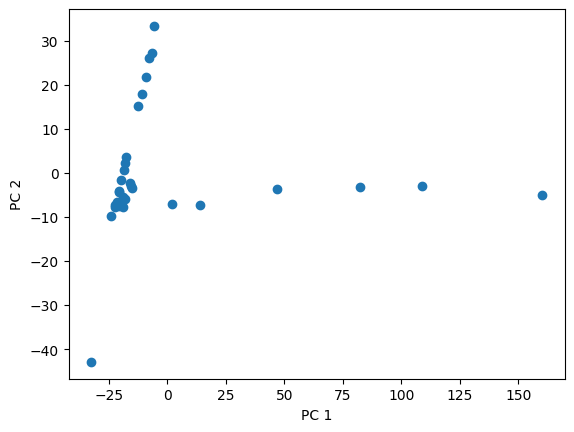

In [ ]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1])
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.show()

# **Clustering Analysis**

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans = KMeans(n_clusters=3, random_state=0)  # kmeans model with given number of clusters

kmeans.fit(X_train)        # fit the model to the data -- data shiould be standardized or normalized

print('Cluster membership:')
print(kmeans.labels_)          # cluster labels
print(kmeans.predict(X_train))

print('\nNumber of samples in clusters:')
print(pd.Series(kmeans.labels_).value_counts())



Cluster membership:
[1 1 1 2 2 1 1 1 2 2 2 1 1 1 1 2 0 0 1 1 1 1 1 0 1 1 1 0 1 1]
[1 1 1 2 2 1 1 1 2 2 2 1 1 1 1 2 0 0 1 1 1 1 1 0 1 1 1 0 1 1]

Number of samples in clusters:
1    20
2     6
0     4
Name: count, dtype: int64


In [ ]:
centers = kmeans.cluster_centers_
print('\nCluster centers (means):')
for (i,c) in enumerate(centers):
    print('Cluster', i, ':', c)


Cluster centers (means):
Cluster 0 : [ 2.     1.01   2.266  2.266  2.266  2.266  2.266  2.266  2.266  2.266  2.266  2.266  2.266  2.269  2.274  2.278  2.281  2.284  2.284  2.283  2.28   2.279  2.278  2.278  2.278  2.279  2.279  2.281
  2.281  2.281  2.281  2.28   2.279  2.281  2.282  2.284  2.284  2.284  2.283  2.282  2.282  2.283  2.283  2.284  2.284  2.285  2.287  2.288  2.287  2.285  2.284  2.285  2.286  2.287  2.288  2.289
  2.289  2.29   2.289  2.289  2.288  2.288  2.288  2.288  2.289  2.291  2.291  2.29   2.289  2.287  2.287  2.287  2.287  2.289  2.29   2.291  2.29   2.29   2.29   2.289  2.288  2.289  2.29   2.29
  2.291  2.29   2.289  2.289  2.29   2.289  2.288  2.29   2.29   2.29   2.291  2.29   2.29   2.29   2.289  2.29   2.29   2.289  2.289  2.29   2.29   2.289  2.288  2.287  2.287  2.288  2.288  2.289
  2.289  2.288  2.288  2.287  2.286  2.286  2.287  2.288  2.288  2.289  2.289  2.288  2.288  2.288  2.287  2.288  2.288  2.29   2.291  2.29   2.29   2.29   2.289  2.288  2.288

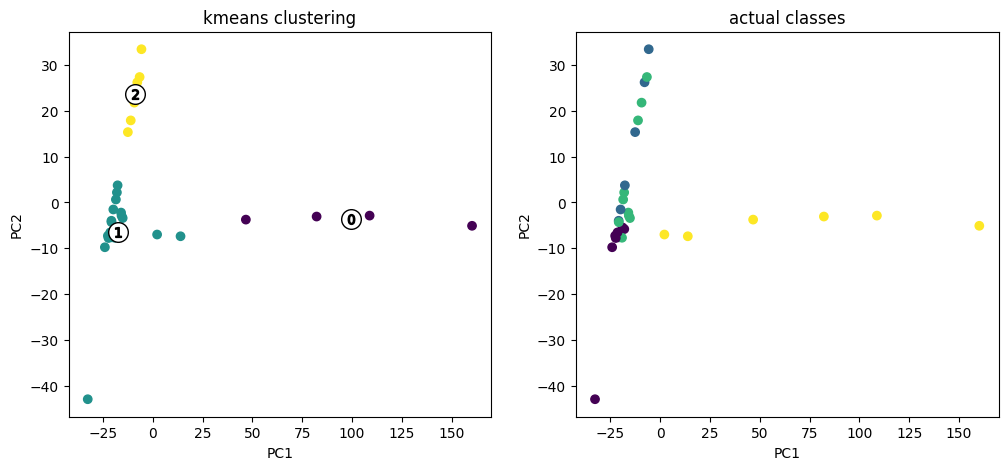

Performance metrics:
  Within-cluster SSE: 11206.532368525186
  Silhouette score:   0.5531189406775229


In [ ]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1, xlabel='PC1', ylabel='PC2', title='kmeans clustering')
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c = kmeans.labels_)  # Color the clusters
plt.scatter(pca.transform(centers)[:,0], pca.transform(centers)[:,1], marker='o', c="white", alpha=1, s=200, edgecolor='k')
for i, c_val in enumerate(centers):
    plt.scatter(pca.transform(c_val.reshape(1,-1))[:,0], pca.transform(c_val.reshape(1,-1))[:,1], marker='$%d$' % i, alpha=1, s=50, edgecolor='k')

plt.subplot(1,2,2, xlabel='PC1', ylabel='PC2', title='actual classes')
# Convert y_train string labels to numerical categories for coloring
y_train_numerical = pd.factorize(y_train)[0]
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c = y_train_numerical)         # Color the actual classes
plt.show()

print('Performance metrics:')
print('  Within-cluster SSE:',  kmeans.inertia_)   # Sum of squared distances of samples to their closest cluster center
print('  Silhouette score:  ',  silhouette_score(X_train, kmeans.labels_))

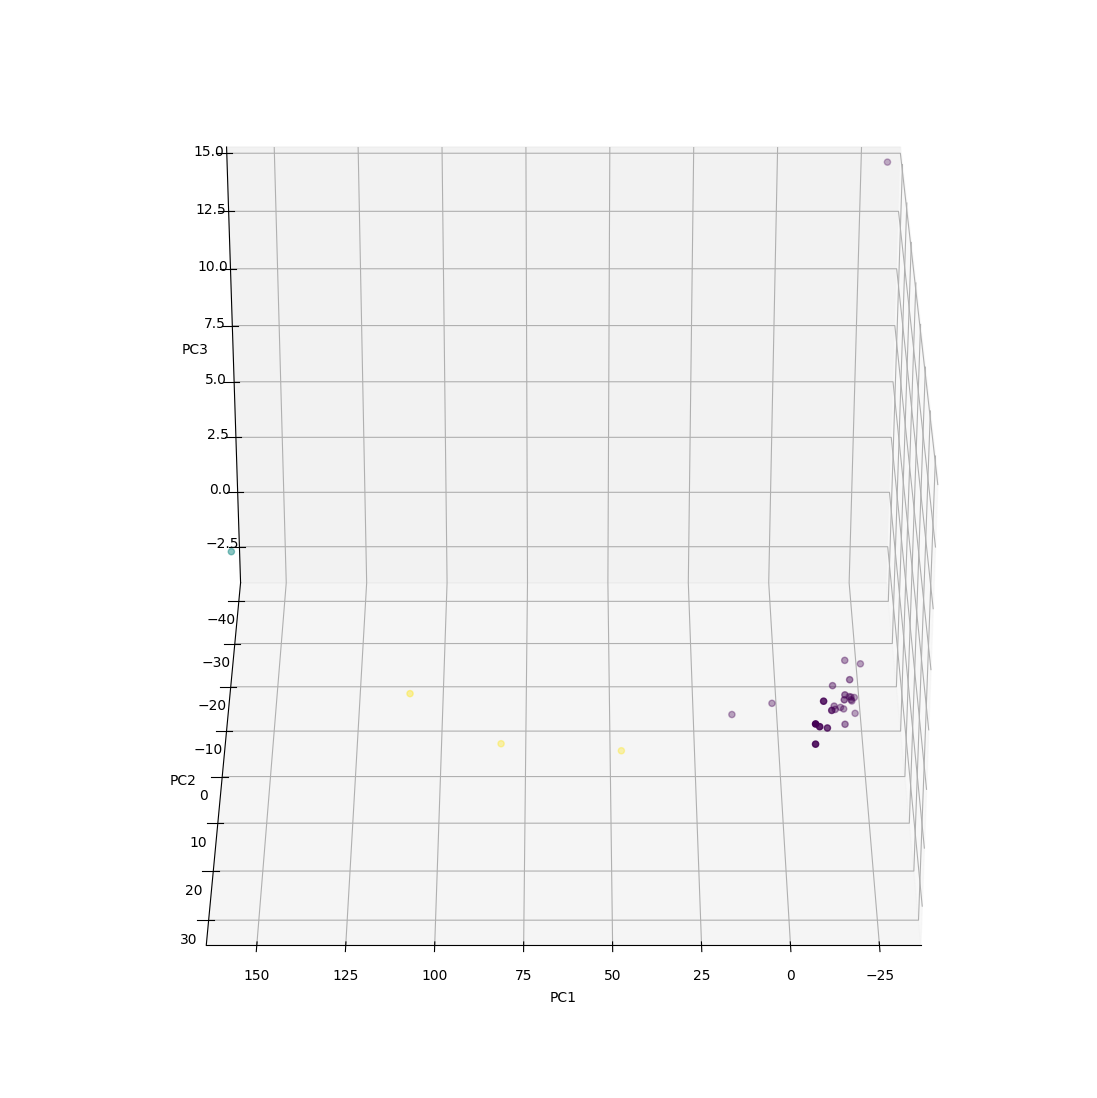

In [ ]:
from sklearn.decomposition import PCA
pca = PCA(n_components=3)

kmeans = KMeans(n_clusters=3)
kmeans.fit(X_train)

X_pca = pca.fit_transform(X_train)

from mpl_toolkits.mplot3d import Axes3D
fig = plt.figure(figsize=(14,14))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2],  c = kmeans.labels_)
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
ax.margins(0.0)
ax.view_init(30, 90)
plt.show()